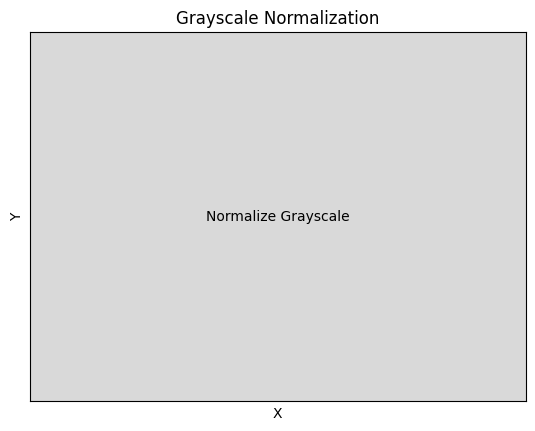

In [1]:
import matplotlib.pyplot as plt

# Create empty lists to store the points
x_values = []
y_values = []
density_values = []

# Function to handle button click event
def normalize_grayscale(event):
    # Clear the lists
    x_values.clear()
    y_values.clear()
    density_values.clear()

    # Clear the plot
    plt.cla()
    plt.title('Grayscale Normalization')
    plt.xlabel('X')
    plt.ylabel('Y')

    # Redraw the plot
    plt.scatter(x_values, y_values, c=density_values, cmap='gray')
    plt.colorbar()

    # Refresh the plot
    plt.draw()

# Create the figure and plot
fig, ax = plt.subplots()
plt.title('Grayscale Normalization')
plt.xlabel('X')
plt.ylabel('Y')

# Connect the button click event to the handler function
button = plt.Button(ax, 'Normalize Grayscale')
button.on_clicked(normalize_grayscale)

# Show the plot
plt.show()


In [ ]:

# Set the input path for the standard document
input_path = "F:/B208/High_density/ML_generation/Standard"


灰度提取

In [8]:
import cv2

# Read the grayscale image
image_path = "F:/B208/High_density/ML_generation/Standard/imgstandard.png"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Define the slice dimensions
WIDTH = 4
LENGTH = 4

# Calculate the average density for each slice
with open("F:/B208/High_density/ML_generation/Standard/imgstandardgray.txt", "w") as file:
    for i in range(0, image.shape[0], LENGTH):
        for j in range(0, image.shape[1], WIDTH):
            x_start = j
            x_end = j + WIDTH
            y_start = i
            y_end = i + LENGTH
            slice = image[y_start:y_end, x_start:x_end]
            average_density = slice.mean()
            file.write(f"{x_start}  {x_end} {y_start} {y_end} {average_density}\n")


In [ ]:
# 假设你有10个灰度-数值的对应关系
gray_values = np.array([0, 32, 64, 96, 128, 160, 192, 224, 255])  # 示例灰度值
corresponding_values = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90])  # 示例对应数值

# 使用线性回归拟合灰度-数值关系
gray_values = gray_values.reshape(-1, 1)  # 转换为二维数组
model = LinearRegression()
model.fit(gray_values, corresponding_values)

# 创建灰度映射表
gray_to_value_map = model.predict(np.arange(256).reshape(-1, 1))

# 调整灰度图
adjusted_image = gray_to_value_map[image].astype(np.uint8)

# 保存调整后的图像
cv2.imwrite("F:/B208/High_density/ML_generation/Standard/adjusted_image.png", adjusted_image)